# Branched flow in a weak random potential

When a wave travels through a medium with weak, smooth random variations, it does not simply
diffuse. Instead it forms a pattern of narrow *branches* that split again and again. The effect was
first imaged for electrons in a two-dimensional electron gas (Topinka et al., Nature **410**, 183
(2001)) and appears for sound waves in the ocean, light in soap films and tsunamis alike
(Heller, Kaplan and Dahlen, Physics Today **74**(4), 44 (2021)).

The ingredients are

* a random potential with correlation length $\ell$ larger than the wavelength $\lambda$,
* a potential much weaker than the kinetic energy, $\delta V \ll E$, so that no particle is reflected.

Small-angle deflections accumulate and focus the classical rays into *caustics*. The first
branches appear after a typical distance $L \sim \ell\,(E/\delta V)^{2/3}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72
plt.rcParams["animation.embed_limit"] = 50  # MB

## The random potential

`RandomPotential2d` draws a Gaussian random field with a prescribed correlation function, here
$C(\Delta r) = \exp(-\Delta r^2/2\ell^2)$, and scales it to a standard deviation $\delta V$.

branching length estimate L ~ 14.736125994561545


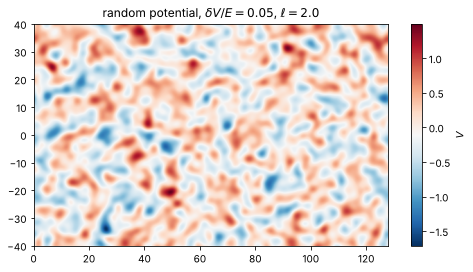

In [2]:
size = ((0.0, 128.0), (-40.0, 40.0))
N = (512, 320)
x = np.linspace(*size[0], N[0], endpoint=False)
y = np.linspace(*size[1], N[1], endpoint=False)

E = 8.0                 # kinetic energy of the wave
k = np.sqrt(2*E)        # wavenumber, wavelength 2 pi/k ~ 1.6
ell = 2.0               # correlation length
dV = 0.05*E             # potential strength

corr = lambda dx, dy: np.exp(-(dx**2 + dy**2)/(2*ell**2))
pot = so.RandomPotential2d(corr, x, y, dV, rng=7)

plt.imshow(pot.values.T, origin="lower", extent=(*size[0], *size[1]), cmap="RdBu_r")
plt.colorbar(label="$V$")
plt.title(f"random potential, $\\delta V/E = {dV/E}$, $\\ell = {ell}$")
print("branching length estimate L ~", ell*(E/dV)**(2/3))

## Launching a wave

A Gaussian wavepacket that is narrow in $y$ starts at the left. Its momentum spread in $y$ makes it
fan out like the beam behind a quantum point contact. An absorbing layer at the edges removes
everything that leaves the box.

In [3]:
absorber = so.BoundaryAbsorber2d(size, width=6.0, strength=3.0)
psi0 = so.Gaussian2d(x0=10.0, y0=0.0, sigma_x=2.0, sigma_y=1.0, px=k)
grid = so.Grid2d(size, N, pot, psi0, absorber=absorber)
prop = so.SplitOperator()

anim = so.animate2d(grid, prop, dt=0.02, n_frames=60, steps_per_frame=25, potential_levels=0, vmax=0.01)
HTML(anim.to_jshtml())

## Time-integrated density

The branches show most clearly in the density summed over the whole passage of the packet,
$\int |\psi(\mathbf{r}, t)|^2\,\mathrm{d}t$. As a reference we also propagate the same packet
without the random potential.

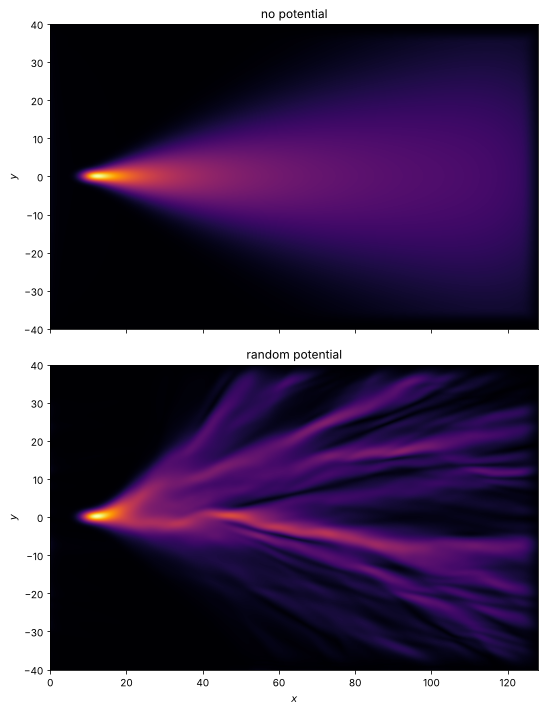

In [4]:
def integrated_density(potential, t_max=30.0, dt=0.02):
    grid = so.Grid2d(size, N, potential, psi0, absorber=absorber)
    acc = np.zeros(N)
    def add(g):
        acc[:] += g.density*dt
    so.SplitOperator().propagate(grid, dt, int(t_max/dt), callback=add)
    return acc

rho_free = integrated_density(so.ConstantPotential(0.0))
rho_rand = integrated_density(pot)

fig, axs = plt.subplots(2, 1, figsize=(9, 10), sharex=True)
for ax, rho, title in zip(axs, [rho_free, rho_rand], ["no potential", "random potential"]):
    ax.imshow(np.sqrt(rho.T), origin="lower", extent=grid.extent, cmap="inferno")
    ax.set(title=title, ylabel="$y$")
axs[1].set_xlabel("$x$")
plt.tight_layout()

## Classical rays

Branched flow is a classical effect at heart: it is caused by the focusing of trajectories.
We integrate Newton's equations $\ddot{\mathbf{r}} = -\nabla V$ for many rays whose initial positions
and momenta are drawn from the Wigner distribution of the initial Gaussian, and histogram where the
rays spend their time.

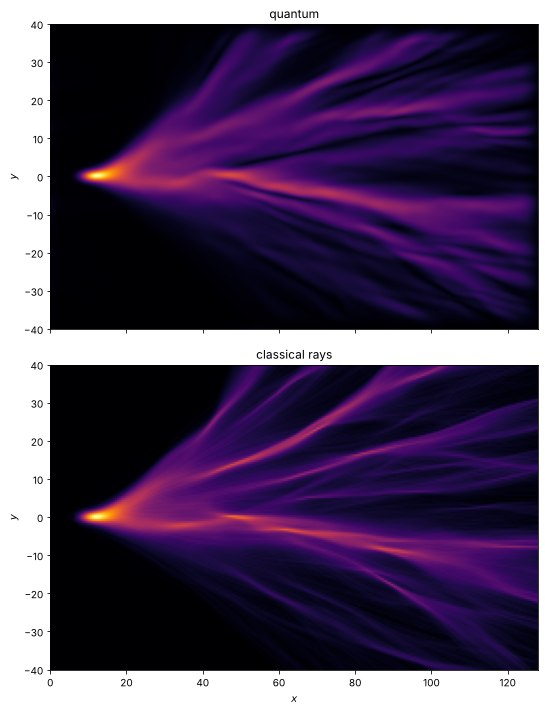

In [5]:
from scipy.interpolate import RegularGridInterpolator

gx, gy = np.gradient(pot.values, x[1] - x[0], y[1] - y[0])
force_x = RegularGridInterpolator((x, y), -gx, bounds_error=False, fill_value=0.0)
force_y = RegularGridInterpolator((x, y), -gy, bounds_error=False, fill_value=0.0)

rng = np.random.default_rng(1)
n_rays = 20000
r = np.stack([rng.normal(10.0, 2.0/np.sqrt(2), n_rays), rng.normal(0.0, 1.0/np.sqrt(2), n_rays)], axis=-1)
p = np.stack([rng.normal(k, 1/(2.0*np.sqrt(2)), n_rays), rng.normal(0.0, 1/(1.0*np.sqrt(2)), n_rays)], axis=-1)

def force(r):
    return np.stack([force_x(r), force_y(r)], axis=-1)

dt, t_max = 0.02, 30.0
bins = [np.linspace(*size[0], 257), np.linspace(*size[1], 161)]
rho_classical = np.zeros((256, 160))
F = force(r)
for i in range(int(t_max/dt)):  # velocity Verlet
    p += 0.5*dt*F
    r += dt*p
    F = force(r)
    p += 0.5*dt*F
    rho_classical += np.histogram2d(r[:, 0], r[:, 1], bins=bins)[0]

fig, axs = plt.subplots(2, 1, figsize=(9, 10), sharex=True)
axs[0].imshow(np.sqrt(rho_rand.T), origin="lower", extent=grid.extent, cmap="inferno")
axs[0].set(title="quantum", ylabel="$y$")
axs[1].imshow(np.sqrt(rho_classical.T), origin="lower", extent=grid.extent, cmap="inferno")
axs[1].set(title="classical rays", xlabel="$x$", ylabel="$y$")
plt.tight_layout()

The main branches coincide. The classical picture shows sharp caustics, where the ray density
formally diverges; the wave smooths them out on the scale of a wavelength and adds interference fringes.

## A stationary picture

Energy filtering the time-dependent wave, $\psi_E(\mathbf{r}) = \int w(t)\,e^{iEt}\,\psi(\mathbf{r}, t)\,\mathrm{d}t$,
gives the stationary flow at a single energy. This is closest to the experiments, which inject
electrons at the Fermi energy. Branches are robust: the pattern hardly changes with energy,
although the interference fringes do.

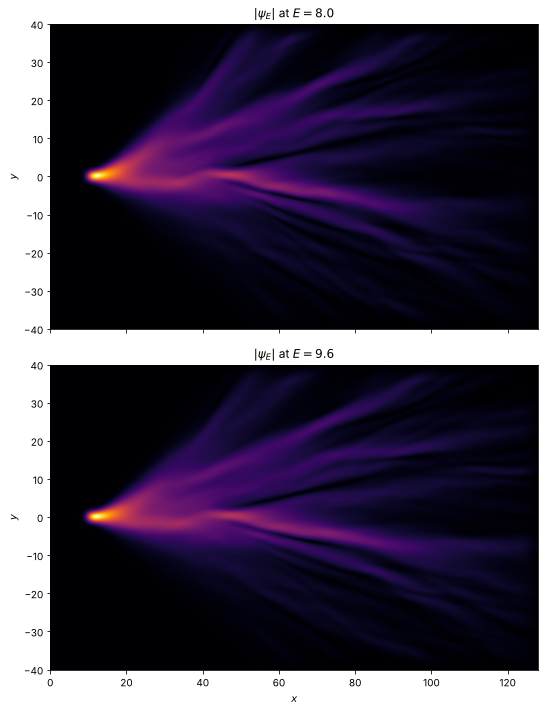

In [6]:
energies = [E, 1.2*E]
grid = so.Grid2d(size, N, pot, so.Gaussian2d(10.0, 0.0, 1.0, 1.0, px=k), absorber=absorber)
t_max, dt = 40.0, 0.02
filt = so.analyzers.EigenstateFilter(energies, t_max)
so.SplitOperator().propagate(grid, dt, int(t_max/dt), callback=lambda g: filt.add_data(g.psi, g.t, dt))

fig, axs = plt.subplots(2, 1, figsize=(9, 10), sharex=True)
for ax, phi, e in zip(axs, filt.eigenstates(grid.dV), energies):
    ax.imshow(np.abs(phi.T), origin="lower", extent=grid.extent, cmap="inferno")
    ax.set(title=f"$|\\psi_E|$ at $E = {e:.1f}$", ylabel="$y$")
axs[1].set_xlabel("$x$")
plt.tight_layout()